In [1]:
import warnings
warnings.filterwarnings('ignore')

import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns

from enigmatoolbox.plotting import plot_cortical, plot_subcortical
import pingouin as pg
from enigmatoolbox.utils.parcellation import parcel_to_surface

import sys
sys.path.append('..')

from helper.func import bayes_factor_interaction

In [2]:
project_dir = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
results_dir = os.path.join(project_dir, 'results', 'Combined_results')

In [ ]:
## Demographics
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'), index_col=0)
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## cortical thickness
ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle.csv'), index_col=0)
ctx_ige = pd.read_csv(os.path.join(results_dir, '...', 'ctx_ige.csv'), index_col=0)

## subcortical volume
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle.csv'), index_col=0)
sv_ige = pd.read_csv(os.path.join(results_dir, '...', 'sv_ige.csv'), index_col=0)

##### We used the Bayesian Information Criterion (BIC) approximation method which provides an approximation to Bayes factor
##### Reference: https://link.springer.com/article/10.3758/BF03194105

### Diagnosis-sex interaction

In [5]:
bayes_results = {}
for epi in ['tle', 'ige']:
    bayes_results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        bayes_results[epi][biomarker] = {}

biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

comparison_types = ['sex_group_interaction']

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        
        df_name = f"{biomarker}_{epi}"
        
        for comparison_type in comparison_types:
            raw_result = bayes_factor_interaction(
                demo=demo, biomarker=biomarker_df, df_name=df_name, comparison_type=comparison_type,
                age_col='Age', sex_col='Sex', icv_col='ICV', group_col='Dx'
            )

            bayes_results[epi][biomarker][comparison_type] = pd.DataFrame(raw_result)

In [ ]:
output_base = os.path.join(results_dir, '...', 'sex_diagnosis_interaction')
os.makedirs(output_base, exist_ok=True)

for epi in bayes_results.keys():

    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)
    
    for biomarker in bayes_results[epi].keys():
        for comparison_type in bayes_results[epi][biomarker].keys():

            df = bayes_results[epi][biomarker][comparison_type].copy()

            df['analysis'] = 'bayes factor interaction'
            df['comparison_type'] = comparison_type
            df['diagnosis'] = epi.upper()
            df['biomarker'] = biomarker

            out_name = f'bayes_{biomarker}_{comparison_type}.csv'

            df.to_csv(os.path.join(epi_dir, out_name), index=False)

##### TLE visualization

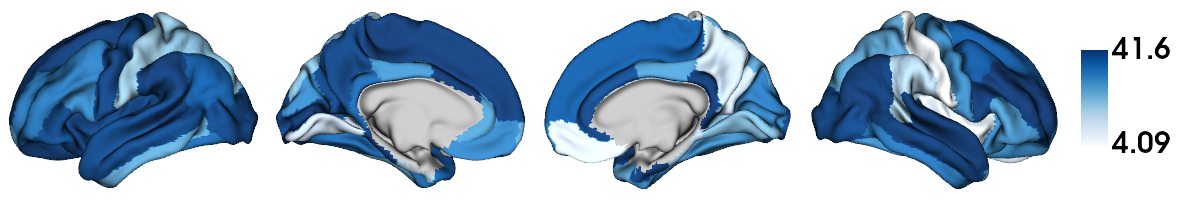

In [ ]:
# plot the BF01 in cortex
surf_data = parcel_to_surface(bayes_results['tle']['ctx']['sex_group_interaction']['BF01'].to_numpy(), 'aparc_conte69')
surf_data[surf_data == 0] = np.nan

plot_cortical(array_name=surf_data, surface_name='conte69', size=(1200, 200), zoom=1.6, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

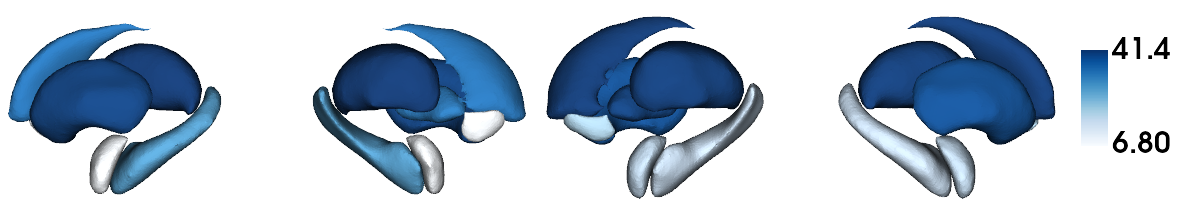

In [11]:
# plot the BF01 in subcortex
plot_subcortical(bayes_results['tle']['sv']['sex_group_interaction']['BF01'], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

##### IGE visualization

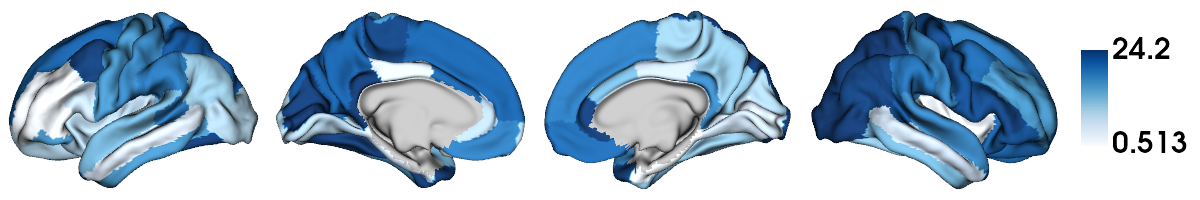

In [12]:
# plot the BF01
surf_data = parcel_to_surface(bayes_results['ige']['ctx']['sex_group_interaction']['BF01'].to_numpy(), 'aparc_conte69')
surf_data[surf_data == 0] = np.nan

plot_cortical(array_name=surf_data, surface_name='conte69', size=(1200, 200), zoom=1.6, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

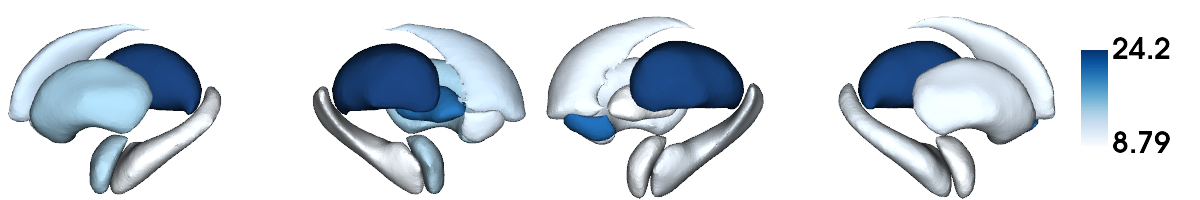

In [13]:
# plot the BF01 in subcortex
plot_subcortical(bayes_results['ige']['sv']['sex_group_interaction']['BF01'], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

### Duration-sex interaction

In [ ]:
## demographics
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## ctx
ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle_durill.csv'), index_col=0)
ctx_ige = pd.read_csv(os.path.join(results_dir, '...', 'ctx_ige_durill.csv'), index_col=0)

## sv
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle_durill.csv'), index_col=0)
sv_ige = pd.read_csv(os.path.join(results_dir, '...', 'sv_ige_durill.csv'), index_col=0)

In [15]:
bayes_results = {}
for epi in ['tle', 'ige']:
    bayes_results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        bayes_results[epi][biomarker] = {}

biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

comparison_types = ['duration_sex_interaction']

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        
        df_name = f"{biomarker}_{epi}"
        
        for comparison_type in comparison_types:
            raw_result = bayes_factor_interaction(
                demo=demo, biomarker=biomarker_df, df_name=df_name, comparison_type=comparison_type,
                age_col='Age', sex_col='Sex', icv_col='ICV', durill_col='durill'
            )

            bayes_results[epi][biomarker][comparison_type] = pd.DataFrame(raw_result)

In [ ]:
output_base = os.path.join(results_dir, '...', 'duration_sex_interaction')
os.makedirs(output_base, exist_ok=True)

for epi in bayes_results.keys():
    
    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)
    
    for biomarker in bayes_results[epi].keys():
        for comparison_type in bayes_results[epi][biomarker].keys():
            
            df = bayes_results[epi][biomarker][comparison_type].copy()

            df['analysis'] = 'bayes factor duration interaction'
            df['comparison_type'] = comparison_type
            df['diagnosis'] = epi.upper()
            df['biomarker'] = biomarker
            
            out_name = f'bayes_{biomarker}_{comparison_type}.csv'
            
            df.to_csv(os.path.join(epi_dir, out_name), index=False)

##### TLE visualization

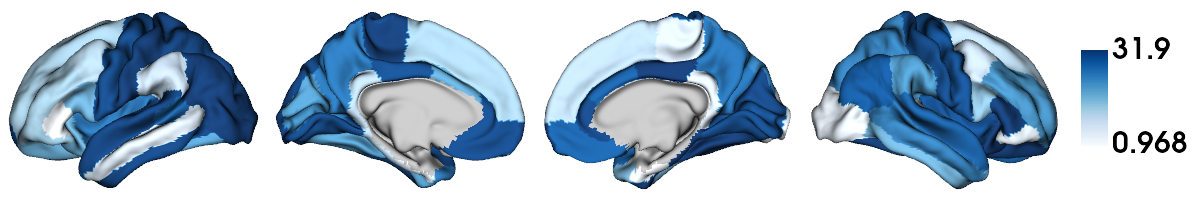

In [17]:
# plot the BF01
surf_data = parcel_to_surface(bayes_results['tle']['ctx']['duration_sex_interaction']['BF01'].to_numpy(), 'aparc_conte69')
surf_data[surf_data == 0] = np.nan

plot_cortical(array_name=surf_data, surface_name='conte69', size=(1200, 200), zoom=1.6, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

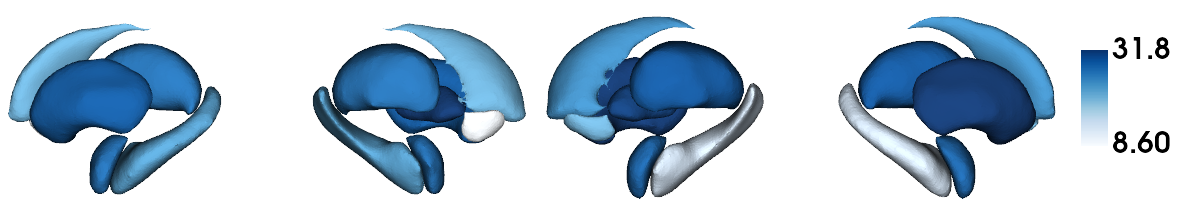

In [18]:
# plot the BF01 in subcortex
plot_subcortical(bayes_results['tle']['sv']['duration_sex_interaction']['BF01'], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

##### IGE visualization

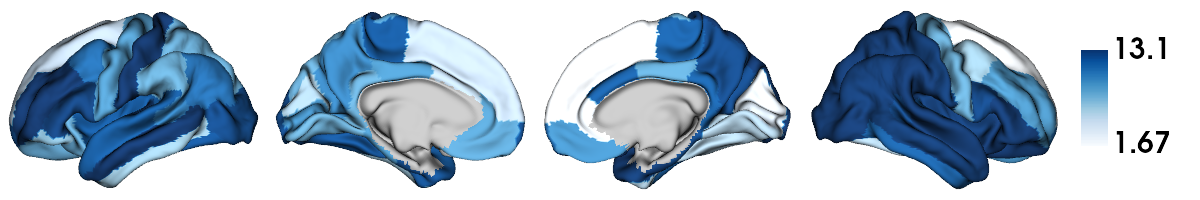

In [19]:
# plot the BF01
surf_data = parcel_to_surface(bayes_results['ige']['ctx']['duration_sex_interaction']['BF01'].to_numpy(), 'aparc_conte69')
surf_data[surf_data == 0] = np.nan

plot_cortical(array_name=surf_data, surface_name='conte69', size=(1200, 200), zoom=1.6, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

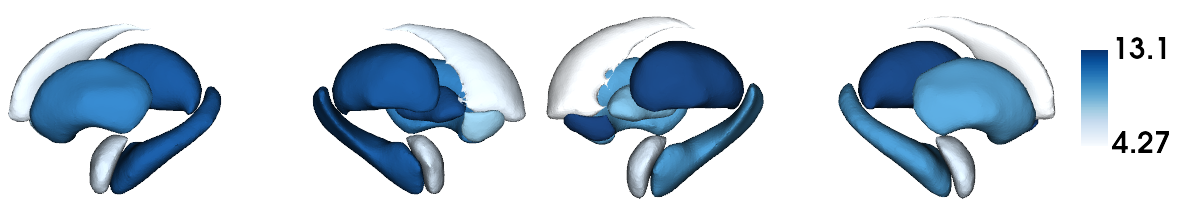

In [20]:
# plot the BF01 in subcortex
plot_subcortical(bayes_results['ige']['sv']['duration_sex_interaction']['BF01'], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

### Onset-sex interaction

In [21]:
bayes_results = {}
for epi in ['tle', 'ige']:
    bayes_results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        bayes_results[epi][biomarker] = {}

biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

comparison_types = ['ao_sex_interaction']

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        
        df_name = f"{biomarker}_{epi}"
        
        for comparison_type in comparison_types:
            raw_result = bayes_factor_interaction(
                demo=demo, biomarker=biomarker_df, df_name=df_name, comparison_type=comparison_type,
                age_col='Age', sex_col='Sex', icv_col='ICV', ao_col='ao'
            )

            bayes_results[epi][biomarker][comparison_type] = pd.DataFrame(raw_result)

In [ ]:
output_base = os.path.join(results_dir, '...', 'onset_sex_interaction')
os.makedirs(output_base, exist_ok=True)

for epi in bayes_results.keys():
    
    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)
    
    for biomarker in bayes_results[epi].keys():
        for comparison_type in bayes_results[epi][biomarker].keys():
            
            df = bayes_results[epi][biomarker][comparison_type].copy()

            df['analysis'] = 'bayes factor onset interaction'
            df['comparison_type'] = comparison_type
            df['diagnosis'] = epi.upper()
            df['biomarker'] = biomarker
            
            out_name = f'bayes_{biomarker}_{comparison_type}.csv'
            
            df.to_csv(os.path.join(epi_dir, out_name), index=False)

##### TLE visualization

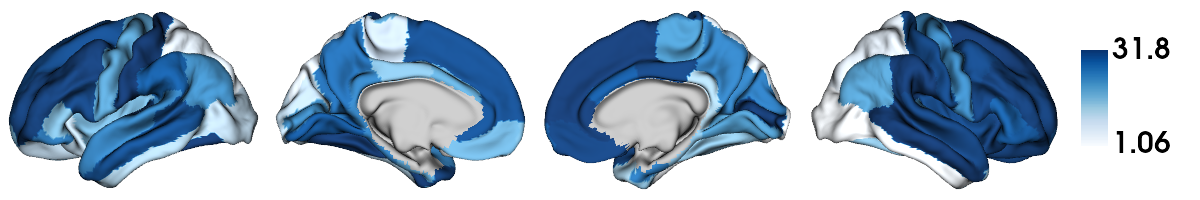

In [ ]:
# plot the BF01
surf_data = parcel_to_surface(bayes_results['tle']['ctx']['ao_sex_interaction']['BF01'].to_numpy(), 'aparc_conte69')
surf_data[surf_data == 0] = np.nan

plot_cortical(array_name=surf_data, surface_name='conte69', size=(1200, 200), zoom=1.6, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

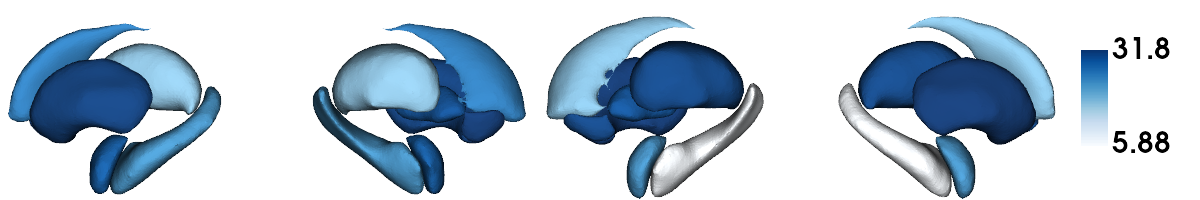

In [25]:
# plot the BF01 in subcortex
plot_subcortical(bayes_results['tle']['sv']['ao_sex_interaction']['BF01'], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

##### IGE visualization

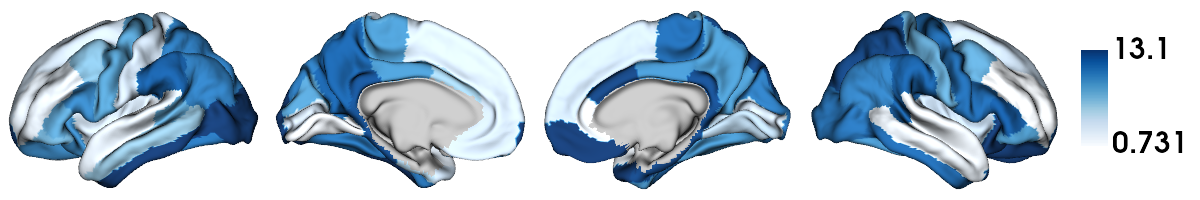

In [26]:
# plot the BF01
surf_data = parcel_to_surface(bayes_results['ige']['ctx']['ao_sex_interaction']['BF01'].to_numpy(), 'aparc_conte69')
surf_data[surf_data == 0] = np.nan

plot_cortical(array_name=surf_data, surface_name='conte69', size=(1200, 200), zoom=1.6, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

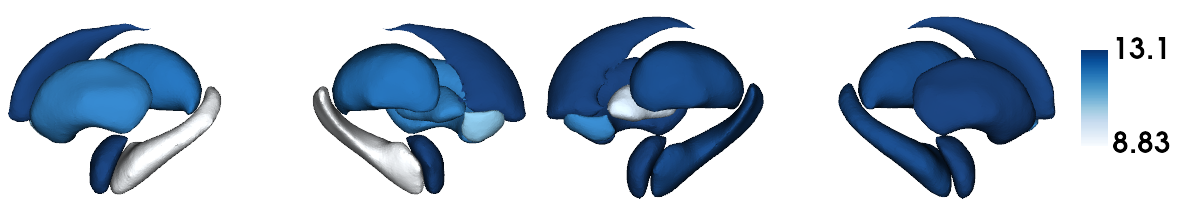

In [27]:
# plot the BF01 in subcortex
plot_subcortical(bayes_results['ige']['sv']['ao_sex_interaction']['BF01'], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

### Age-sex interaction

In [28]:
bayes_results = {}
for epi in ['tle', 'ige']:
    bayes_results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        bayes_results[epi][biomarker] = {}

biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

comparison_types = ['age_sex_interaction']

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        
        df_name = f"{biomarker}_{epi}"
        
        for comparison_type in comparison_types:
            raw_result = bayes_factor_interaction(
                demo=demo, biomarker=biomarker_df, df_name=df_name, comparison_type=comparison_type,
                age_col='Age', sex_col='Sex', icv_col='ICV'
            )

            bayes_results[epi][biomarker][comparison_type] = pd.DataFrame(raw_result)

In [ ]:
output_base = os.path.join(results_dir, '...', 'age_sex_interaction')
os.makedirs(output_base, exist_ok=True)

for epi in bayes_results.keys():
    
    epi_dir = os.path.join(output_base, epi.upper())
    os.makedirs(epi_dir, exist_ok=True)
    
    for biomarker in bayes_results[epi].keys():
        for comparison_type in bayes_results[epi][biomarker].keys():
            
            df = bayes_results[epi][biomarker][comparison_type].copy()

            df['analysis'] = 'bayes factor age interaction'
            df['comparison_type'] = comparison_type
            df['diagnosis'] = epi.upper()
            df['biomarker'] = biomarker
            
            out_name = f'bayes_{biomarker}_{comparison_type}.csv'
            
            df.to_csv(os.path.join(epi_dir, out_name), index=False)

##### TLE visualization

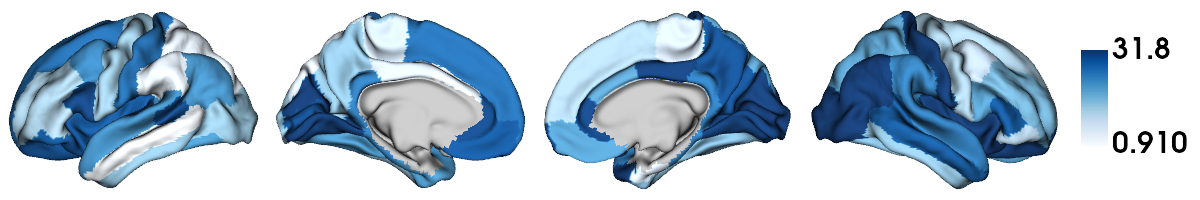

In [30]:
# plot the BF01
surf_data = parcel_to_surface(bayes_results['tle']['ctx']['age_sex_interaction']['BF01'].to_numpy(), 'aparc_conte69')
surf_data[surf_data == 0] = np.nan

plot_cortical(array_name=surf_data, surface_name='conte69', size=(1200, 200), zoom=1.6, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

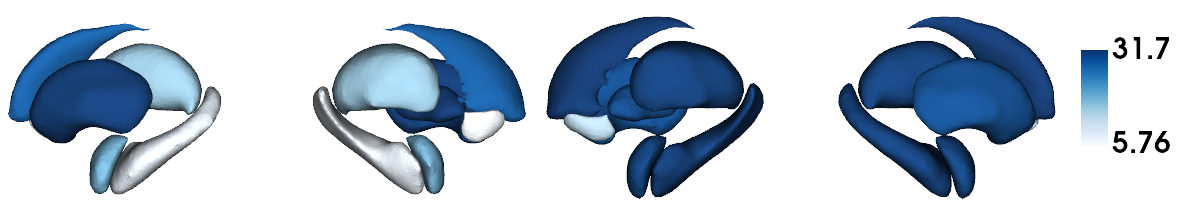

In [31]:
# plot the BF01 in subcortex
plot_subcortical(bayes_results['tle']['sv']['age_sex_interaction']['BF01'], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

##### IGE visualization

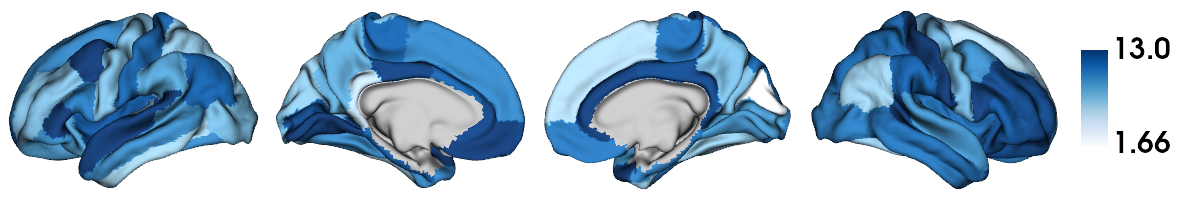

In [32]:
# plot the BF01
surf_data = parcel_to_surface(bayes_results['ige']['ctx']['age_sex_interaction']['BF01'].to_numpy(), 'aparc_conte69')
surf_data[surf_data == 0] = np.nan

plot_cortical(array_name=surf_data, surface_name='conte69', size=(1200, 200), zoom=1.6, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})

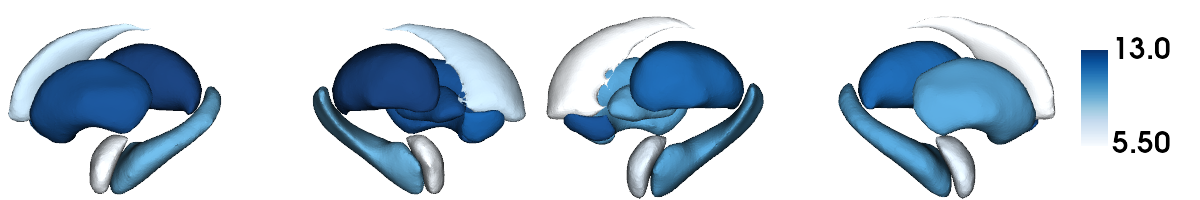

In [33]:
# plot the BF01 in subcortex
plot_subcortical(bayes_results['ige']['sv']['age_sex_interaction']['BF01'], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='Blues', color_bar=True, color_range='sym', cb__labelTextProperty={'fontSize': 30})